In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from itertools import combinations

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix
)
from sklearn.inspection import permutation_importance
from scipy.stats import spearmanr

import shap
from lime.lime_tabular import LimeTabularExplainer

out_dir = "xai_outputs_heart"
os.makedirs(out_dir, exist_ok=True)

# -----------------------------
# 1. Load and preprocess exactly as replication
# -----------------------------
file_path = "../../data/heart/processed.cleveland.data"

column_names = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs',
    'restecg', 'thalach', 'exang', 'oldpeak',
    'slope', 'ca', 'thal', 'target'
]

df = pd.read_csv(file_path, names=column_names)
df.replace('?', np.nan, inplace=True)

for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df = df.dropna().copy()
df['target'] = df['target'].apply(lambda x: 1 if x > 0 else 0)

X_df = df.drop('target', axis=1).copy()
y = df['target'].copy()
feature_names = X_df.columns.tolist()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_df)
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_names, index=X_df.index)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled_df, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# -----------------------------
# 2. Final explained model = LR 10-fold
# -----------------------------
final_model = LogisticRegressionCV(
    Cs=10,
    cv=10,
    penalty='l2',
    solver='liblinear',
    max_iter=1000,
    random_state=42
)

final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

print("Final XAI model: Logistic Regression (10-fold CV)")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1       :", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("AUC      :", round(roc_auc_score(y_test, y_prob), 4))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))


c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Final XAI model: Logistic Regression (10-fold CV)
Accuracy : 0.8667
Precision: 0.8947
Recall   : 0.8095
F1       : 0.85
AUC      : 0.9439

Confusion matrix:
[[44  4]
 [ 8 34]]



Logistic regression coefficients
     Feature  Coefficient  AbsCoefficient
12      thal       0.4788          0.4788
11        ca       0.4443          0.4443
2         cp       0.3343          0.3343
8      exang       0.3122          0.3122
1        sex       0.2821          0.2821
9    oldpeak       0.2486          0.2486
7    thalach      -0.2205          0.2205
6    restecg       0.1888          0.1888
10     slope       0.1862          0.1862
3   trestbps       0.1689          0.1689
5        fbs      -0.1251          0.1251
4       chol       0.0998          0.0998
0        age       0.0815          0.0815


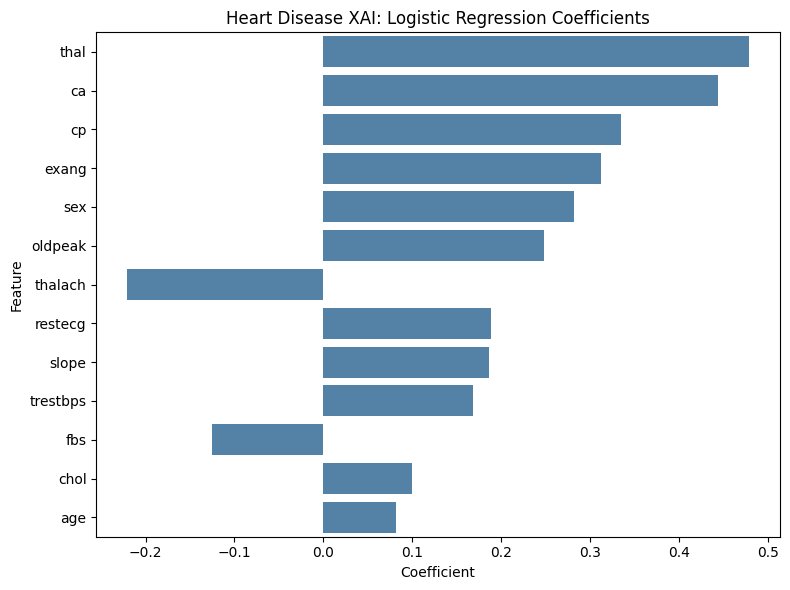

In [2]:
# -----------------------------
# 3. Global XAI: coefficients
# -----------------------------
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": final_model.coef_[0],
    "AbsCoefficient": np.abs(final_model.coef_[0])
}).sort_values("AbsCoefficient", ascending=False)

print("\nLogistic regression coefficients")
print(coef_df.round(4))

plt.figure(figsize=(8, 6))
sns.barplot(data=coef_df, x="Coefficient", y="Feature", color="steelblue")
plt.title("Heart Disease XAI: Logistic Regression Coefficients")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "heart_lr_coefficients.png"), dpi=300)
plt.show()



Permutation importance
     Feature  PermutationMean  PermutationStd
11        ca           0.0451          0.0152
12      thal           0.0263          0.0178
2         cp           0.0171          0.0070
1        sex           0.0142          0.0081
8      exang           0.0104          0.0066
7    thalach           0.0091          0.0060
9    oldpeak           0.0052          0.0059
3   trestbps           0.0020          0.0045
5        fbs           0.0009          0.0032
10     slope           0.0008          0.0034
6    restecg          -0.0000          0.0053
4       chol          -0.0003          0.0019
0        age          -0.0006          0.0022


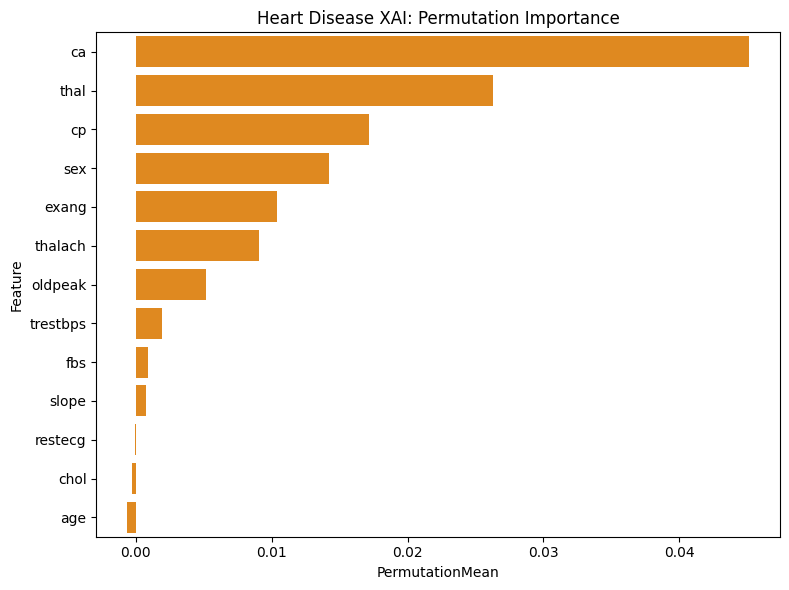

In [3]:
# -----------------------------
# 4. Global XAI: permutation importance
# -----------------------------
perm = permutation_importance(
    final_model,
    X_test,
    y_test,
    n_repeats=30,
    random_state=42,
    scoring="roc_auc"
)

perm_df = pd.DataFrame({
    "Feature": feature_names,
    "PermutationMean": perm.importances_mean,
    "PermutationStd": perm.importances_std
}).sort_values("PermutationMean", ascending=False)

print("\nPermutation importance")
print(perm_df.round(4))

plt.figure(figsize=(8, 6))
sns.barplot(data=perm_df, x="PermutationMean", y="Feature", color="darkorange")
plt.title("Heart Disease XAI: Permutation Importance")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "heart_permutation_importance.png"), dpi=300)
plt.show()


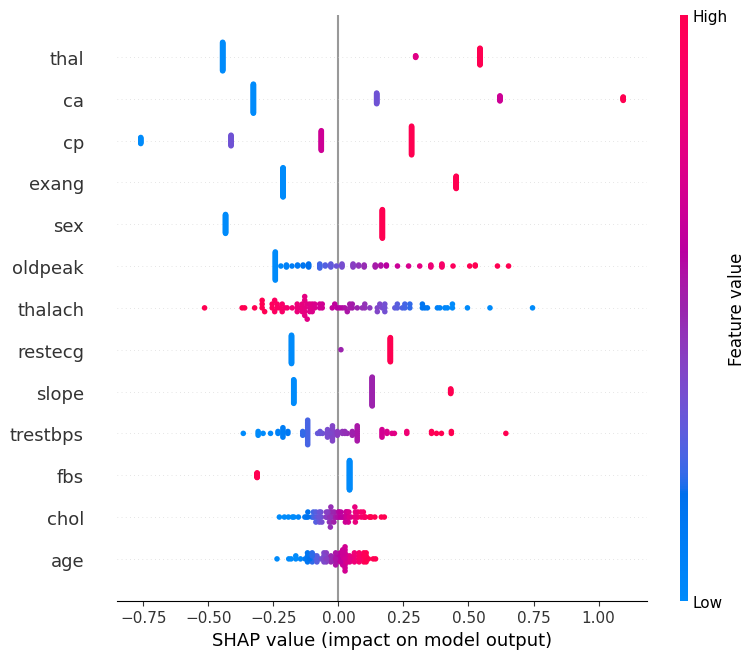

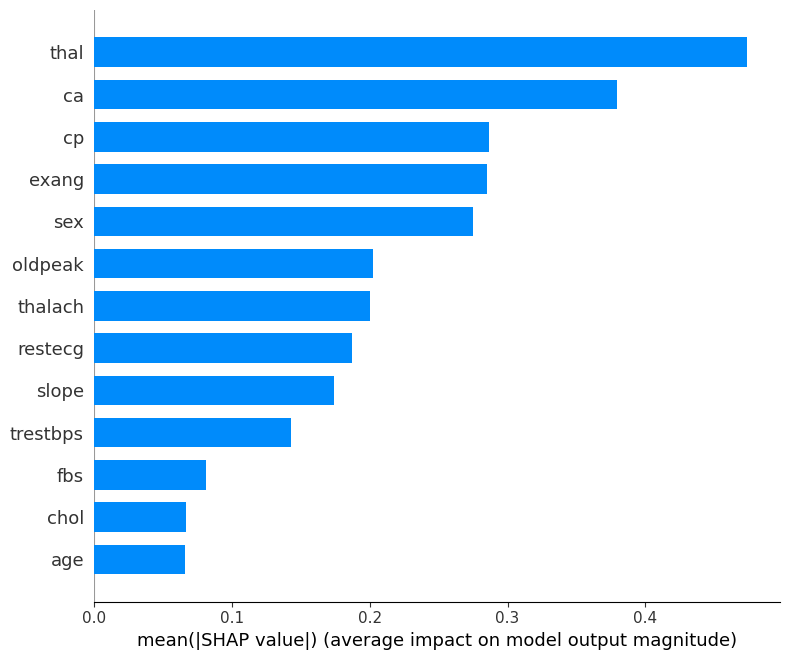


SHAP importance
     Feature  MeanAbsSHAP
12      thal       0.4739
11        ca       0.3794
2         cp       0.2865
8      exang       0.2849
1        sex       0.2750
9    oldpeak       0.2028
7    thalach       0.2002
6    restecg       0.1873
10     slope       0.1740
3   trestbps       0.1430
5        fbs       0.0817
4       chol       0.0669
0        age       0.0664


In [4]:
# -----------------------------
# 5. Global XAI: SHAP importance
# -----------------------------
explainer = shap.LinearExplainer(final_model, X_train)
shap_values = explainer.shap_values(X_test)

shap_values = np.array(shap_values)
if shap_values.ndim == 3:
    shap_plot_values = shap_values[:, :, 1]
else:
    shap_plot_values = shap_values

shap.summary_plot(shap_plot_values, X_test, show=False)
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "heart_shap_summary.png"), dpi=300, bbox_inches="tight")
plt.show()

shap.summary_plot(shap_plot_values, X_test, plot_type="bar", show=False)
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "heart_shap_bar.png"), dpi=300, bbox_inches="tight")
plt.show()

shap_imp = pd.DataFrame({
    "Feature": feature_names,
    "MeanAbsSHAP": np.abs(shap_plot_values).mean(axis=0)
}).sort_values("MeanAbsSHAP", ascending=False)

print("\nSHAP importance")
print(shap_imp.round(4))


In [5]:
# -----------------------------
# 6. Compare coefficient vs SHAP vs permutation
# -----------------------------
coef_rank = coef_df[["Feature", "AbsCoefficient"]].reset_index(drop=True).copy()
coef_rank["CoefficientRank"] = np.arange(1, len(coef_rank) + 1)

shap_rank = shap_imp[["Feature", "MeanAbsSHAP"]].reset_index(drop=True).copy()
shap_rank["SHAPRank"] = np.arange(1, len(shap_rank) + 1)

perm_rank = perm_df[["Feature", "PermutationMean"]].reset_index(drop=True).copy()
perm_rank["PermutationRank"] = np.arange(1, len(perm_rank) + 1)

rank_compare = coef_rank.merge(
    shap_rank, on="Feature", how="left"
).merge(
    perm_rank, on="Feature", how="left"
)

rho_coef_shap, p_coef_shap = spearmanr(rank_compare["CoefficientRank"], rank_compare["SHAPRank"])
rho_shap_perm, p_shap_perm = spearmanr(rank_compare["SHAPRank"], rank_compare["PermutationRank"])

print("\nCoefficient vs SHAP vs Permutation comparison")
print(rank_compare.round(4))
print(f"\nSpearman coefficient vs SHAP: {rho_coef_shap:.4f} (p={p_coef_shap:.4f})")
print(f"Spearman SHAP vs permutation: {rho_shap_perm:.4f} (p={p_shap_perm:.4f})")



Coefficient vs SHAP vs Permutation comparison
     Feature  AbsCoefficient  CoefficientRank  MeanAbsSHAP  SHAPRank  \
0       thal          0.4788                1       0.4739         1   
1         ca          0.4443                2       0.3794         2   
2         cp          0.3343                3       0.2865         3   
3      exang          0.3122                4       0.2849         4   
4        sex          0.2821                5       0.2750         5   
5    oldpeak          0.2486                6       0.2028         6   
6    thalach          0.2205                7       0.2002         7   
7    restecg          0.1888                8       0.1873         8   
8      slope          0.1862                9       0.1740         9   
9   trestbps          0.1689               10       0.1430        10   
10       fbs          0.1251               11       0.0817        11   
11      chol          0.0998               12       0.0669        12   
12       age     


Top 3 SHAP features: ['thal', 'ca', 'cp']


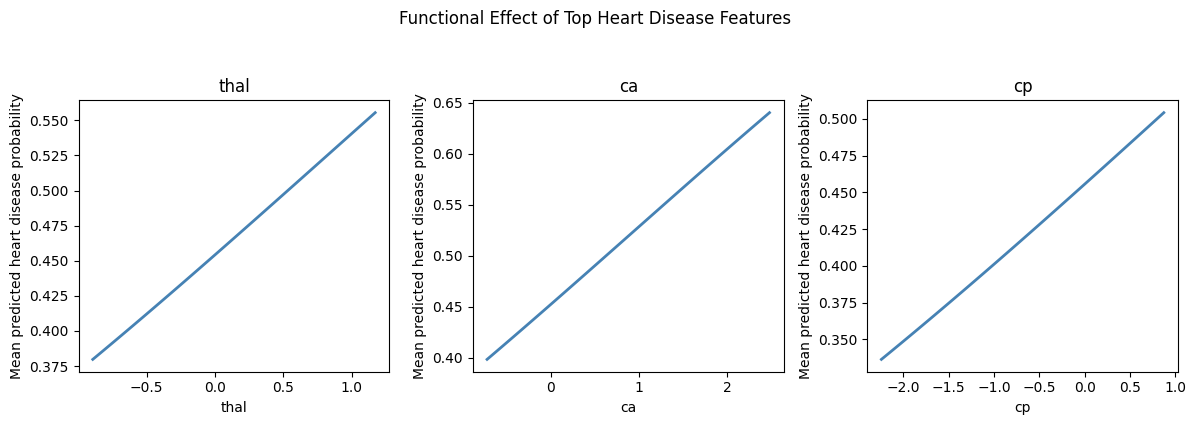

In [6]:
# -----------------------------
# 7. Functional XAI: manual probability profiles
# -----------------------------
top_features = shap_imp["Feature"].head(3).tolist()
print("\nTop 3 SHAP features:", top_features)

fig, axes = plt.subplots(1, len(top_features), figsize=(12, 4))

if len(top_features) == 1:
    axes = [axes]

X_ref = X_test.copy()

for ax, feat in zip(axes, top_features):
    grid = np.linspace(
        X_ref[feat].quantile(0.01),
        X_ref[feat].quantile(0.99),
        80
    )

    mean_probs = []

    for val in grid:
        X_temp = X_ref.copy()
        X_temp[feat] = val
        probs = final_model.predict_proba(X_temp)[:, 1]
        mean_probs.append(probs.mean())

    ax.plot(grid, mean_probs, color="steelblue", linewidth=2)
    ax.set_title(feat)
    ax.set_xlabel(feat)
    ax.set_ylabel("Mean predicted heart disease probability")

fig.suptitle("Functional Effect of Top Heart Disease Features", y=1.05)
plt.tight_layout()
fig.savefig(os.path.join(out_dir, "heart_functional_profiles_top3.png"), dpi=300, bbox_inches="tight")
plt.show()


In [7]:
# -----------------------------
# 8. Local XAI: representative cases
# -----------------------------
case_df = X_test.copy()
case_df["y_true"] = y_test.values
case_df["y_pred"] = y_pred
case_df["y_prob"] = y_prob
case_df["dist_to_05"] = np.abs(case_df["y_prob"] - 0.5)

tp = case_df[
    (case_df["y_true"] == 1) & (case_df["y_pred"] == 1)
].sort_values("y_prob", ascending=False).head(1).copy()

tn = case_df[
    (case_df["y_true"] == 0) & (case_df["y_pred"] == 0)
].sort_values("y_prob", ascending=True).head(1).copy()

fp = case_df[
    (case_df["y_true"] == 0) & (case_df["y_pred"] == 1)
].sort_values("y_prob", ascending=False).head(1).copy()

fn = case_df[
    (case_df["y_true"] == 1) & (case_df["y_pred"] == 0)
].sort_values("y_prob", ascending=True).head(1).copy()

borderline = case_df.sort_values("dist_to_05").head(1).copy()

tp["CaseType"] = "TP"
tn["CaseType"] = "TN"
fp["CaseType"] = "FP"
fn["CaseType"] = "FN"
borderline["CaseType"] = "Borderline"

rep_cases = pd.concat([tp, tn, fp, fn, borderline]).drop_duplicates()

print("\nRepresentative cases")
print(rep_cases.round(4))

rep_indices = rep_cases.index.tolist()

rep_cases.to_csv(os.path.join(out_dir, "heart_representative_cases.csv"), index=True)



Representative cases
        age     sex      cp  trestbps    chol     fbs  restecg  thalach  \
126  0.1614 -1.4470  0.8739    3.8520  0.7831  2.4304   1.0102  -0.7248   
216 -0.9455 -1.4470 -1.2025   -1.5053 -0.8351 -0.4115  -1.0034   0.9781   
252  1.0469  0.6911  0.8739   -0.2083  0.3015 -0.4115  -1.0034  -1.9473   
124  1.1576  0.6911 -2.2406    0.3556  0.6675  2.4304   1.0102   1.0654   
246  0.3827  0.6911  0.8739   -1.7873 -0.2572 -0.4115  -1.0034   0.2795   

      exang  oldpeak   slope      ca    thal  y_true  y_pred  y_prob  \
126  1.4359   2.5292  2.2641  1.4116  1.1726       1       1  0.9618   
216 -0.6964  -0.9067 -0.9766 -0.7220 -0.8942       0       0  0.0437   
252  1.4359  -0.7349  0.6438  0.3448  1.1726       0       1  0.8611   
124 -0.6964   0.2959  0.6438  0.3448 -0.8942       1       0  0.2471   
246 -0.6964  -0.8208 -0.9766  0.3448  1.1726       1       0  0.4921   

     dist_to_05    CaseType  
126      0.4618          TP  
216      0.4563          TN  
252 


SHAP local explanation for case 126
CaseType          TP
y_true             1
y_pred             1
y_prob      0.961788
Name: 126, dtype: object


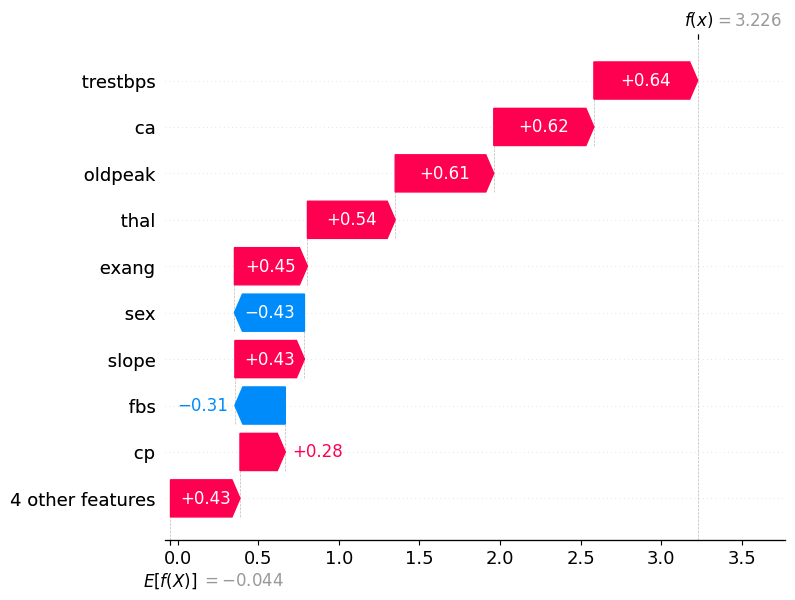

<Figure size 640x480 with 0 Axes>


SHAP local explanation for case 216
CaseType          TN
y_true             0
y_pred             0
y_prob      0.043685
Name: 216, dtype: object


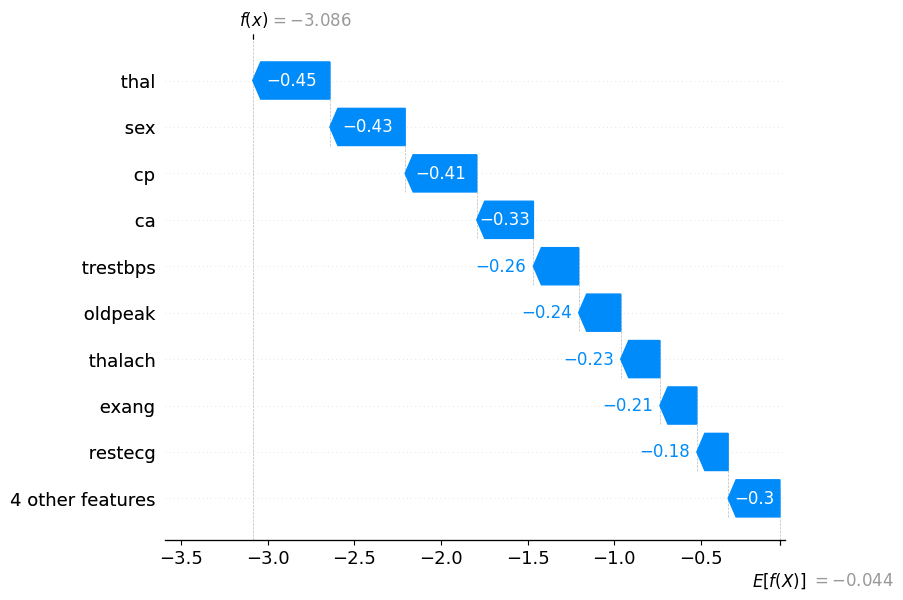

<Figure size 640x480 with 0 Axes>


SHAP local explanation for case 252
CaseType          FP
y_true             0
y_pred             1
y_prob      0.861122
Name: 252, dtype: object


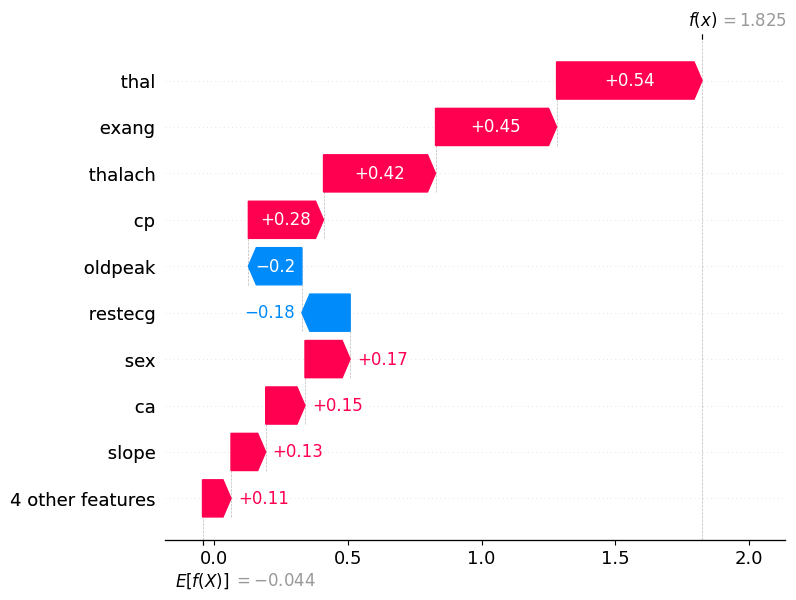

<Figure size 640x480 with 0 Axes>


SHAP local explanation for case 124
CaseType          FN
y_true             1
y_pred             0
y_prob      0.247055
Name: 124, dtype: object


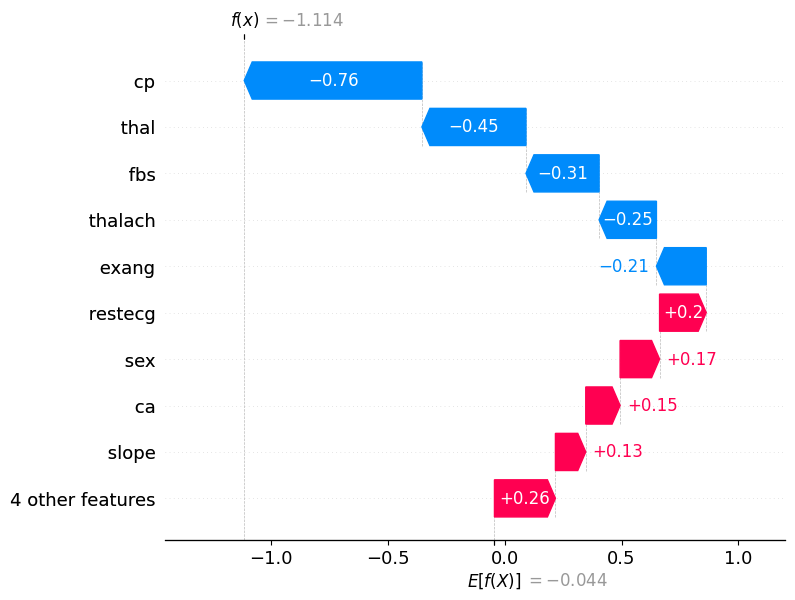

<Figure size 640x480 with 0 Axes>


SHAP local explanation for case 246
CaseType    Borderline
y_true               1
y_pred               0
y_prob        0.492082
Name: 246, dtype: object


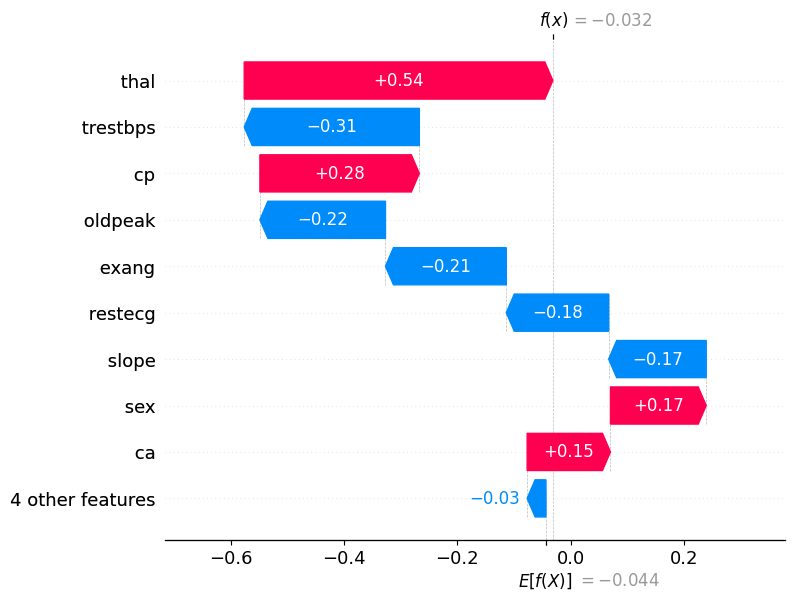

<Figure size 640x480 with 0 Axes>

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegressionCV was fitted with feature names
  warnings.warn(



LIME explanation for case 126
CaseType          TP
y_true             1
y_pred             1
y_prob      0.961788
Name: 126, dtype: object
[('ca > 0.34', 0.13396841643644863), ('-0.16 < cp <= 0.87', 0.1285806806121983), ('-0.89 < thal <= 1.17', 0.09624162218600263), ('-0.70 < exang <= 1.44', 0.09152941859414866), ('oldpeak > 0.47', 0.0831707626369484), ('thalach <= -0.44', 0.07965950983745705), ('fbs > -0.41', -0.07227549878918861), ('slope > 0.64', 0.06888937729955899)]


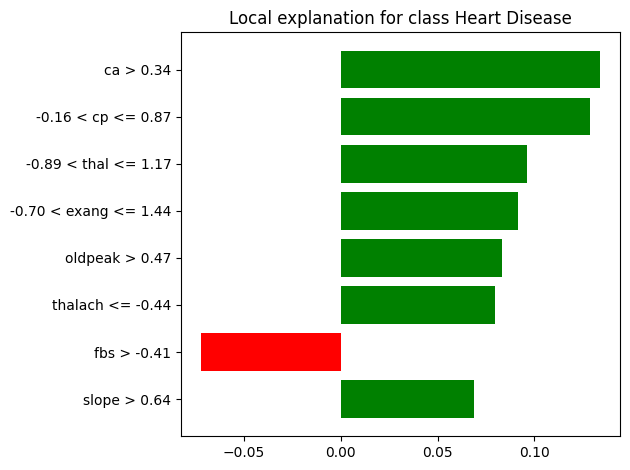

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegressionCV was fitted with feature names
  warnings.warn(



LIME explanation for case 216
CaseType          TN
y_true             0
y_pred             0
y_prob      0.043685
Name: 216, dtype: object
[('cp <= -0.16', -0.1280555717729996), ('thal <= -0.89', -0.09876085241251333), ('exang <= -0.70', -0.09263125392930015), ('ca <= -0.72', -0.086602116473543), ('thalach > 0.76', -0.07534901449560645), ('fbs <= -0.41', 0.07160413543892617), ('trestbps <= -0.66', -0.05784847334776659), ('sex <= -1.45', -0.0372340720329513)]


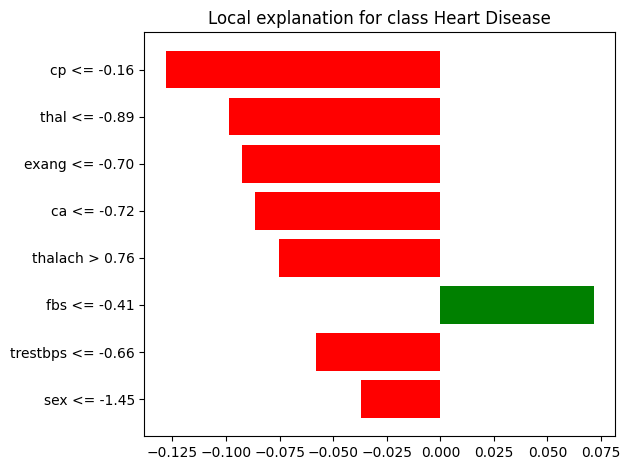

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegressionCV was fitted with feature names
  warnings.warn(



LIME explanation for case 252
CaseType          FP
y_true             0
y_pred             1
y_prob      0.861122
Name: 252, dtype: object
[('-0.16 < cp <= 0.87', 0.13191903194332052), ('-0.89 < thal <= 1.17', 0.09990673255087482), ('-0.70 < exang <= 1.44', 0.08599829767924971), ('thalach <= -0.44', 0.08248130601553595), ('fbs <= -0.41', 0.06275007292143828), ('-0.91 < oldpeak <= -0.22', -0.05513388357000064), ('-1.45 < sex <= 0.69', 0.03877368403895471), ('age > 0.71', 0.031223221321289255)]


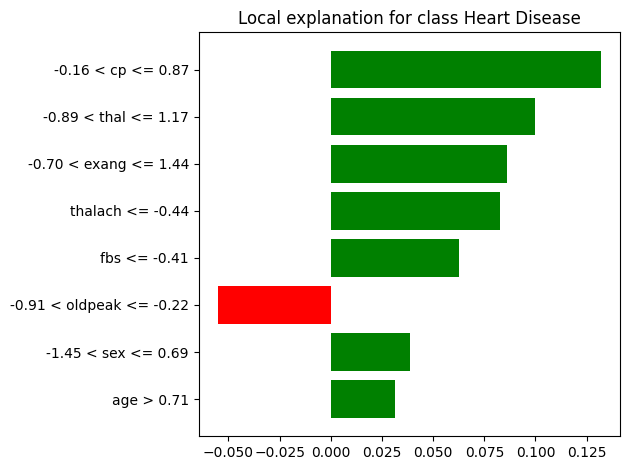

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegressionCV was fitted with feature names
  warnings.warn(



LIME explanation for case 124
CaseType          FN
y_true             1
y_pred             0
y_prob      0.247055
Name: 124, dtype: object
[('cp <= -0.16', -0.12683454803357136), ('thal <= -0.89', -0.09839292318834147), ('exang <= -0.70', -0.09237977238044724), ('thalach > 0.76', -0.07101872285152834), ('fbs > -0.41', -0.06885170852933349), ('-1.45 < sex <= 0.69', 0.05016017541152355), ('chol > 0.58', 0.03754391551552537), ('-1.00 < restecg <= 1.01', 0.03658664887557471)]


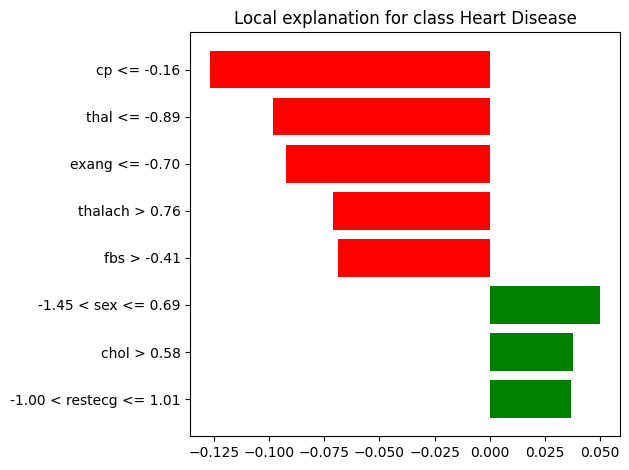

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegressionCV was fitted with feature names
  warnings.warn(



LIME explanation for case 246
CaseType    Borderline
y_true               1
y_pred               0
y_prob        0.492082
Name: 246, dtype: object
[('-0.16 < cp <= 0.87', 0.12651783503694336), ('-0.89 < thal <= 1.17', 0.09992098666593838), ('exang <= -0.70', -0.09073199875899278), ('fbs <= -0.41', 0.0628810512144572), ('-0.91 < oldpeak <= -0.22', -0.05912715618796408), ('trestbps <= -0.66', -0.05020206989177435), ('-1.45 < sex <= 0.69', 0.041276569263062016), ('slope <= -0.98', -0.03239548477531792)]


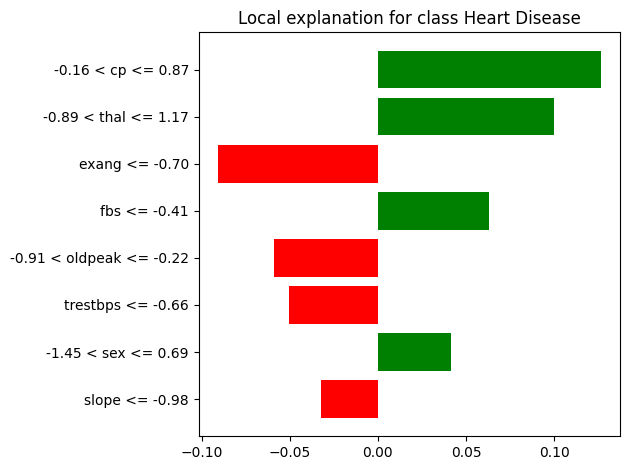

In [8]:
# -----------------------------
# 9. SHAP local explanations
# -----------------------------
for idx in rep_indices:
    row = X_test.loc[[idx]]

    shap_single = explainer.shap_values(row)
    shap_single = np.array(shap_single)

    if shap_single.ndim == 3:
        shap_single_plot = shap_single[:, :, 1]
        local_expected = explainer.expected_value[1]
    else:
        shap_single_plot = shap_single
        local_expected = explainer.expected_value

    print(f"\nSHAP local explanation for case {idx}")
    print(rep_cases.loc[idx, ["CaseType", "y_true", "y_pred", "y_prob"]])

    plt.figure()
    shap.plots._waterfall.waterfall_legacy(
        local_expected,
        shap_single_plot[0],
        feature_names=row.columns.tolist(),
        features=row.iloc[0].values
    )
    plt.tight_layout()
    plt.savefig(
        os.path.join(out_dir, f"heart_shap_waterfall_case_{idx}.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

# -----------------------------
# 10. LIME local explanations
# -----------------------------
lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=feature_names,
    class_names=["No Heart Disease", "Heart Disease"],
    mode="classification"
)

lime_rows = []

for idx in rep_indices:
    exp = lime_explainer.explain_instance(
        X_test.loc[idx].values,
        final_model.predict_proba,
        num_features=min(8, len(feature_names))
    )

    print(f"\nLIME explanation for case {idx}")
    print(rep_cases.loc[idx, ["CaseType", "y_true", "y_pred", "y_prob"]])
    print(exp.as_list())

    for feat, weight in exp.as_list():
        lime_rows.append({
            "CaseIndex": idx,
            "CaseType": rep_cases.loc[idx, "CaseType"],
            "Rule": feat,
            "Weight": weight
        })

    fig = exp.as_pyplot_figure()
    plt.tight_layout()
    plt.savefig(
        os.path.join(out_dir, f"heart_lime_case_{idx}.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

lime_df = pd.DataFrame(lime_rows)



Stability summary
          MeanImportance  StdImportance  MeanRank  StdRank
Feature                                                   
ca                0.0441         0.0130       1.0   0.0000
thal              0.0284         0.0039       2.0   0.0000
cp                0.0173         0.0062       4.0   1.2247
exang             0.0134         0.0046       4.8   1.4832
sex               0.0149         0.0081       5.2   1.9235
thalach           0.0070         0.0045       6.8   2.5884
oldpeak           0.0086         0.0070       6.8   2.5884
trestbps          0.0036         0.0059       9.4   3.2094
slope             0.0036         0.0023       9.6   1.5166
restecg           0.0024         0.0062      10.0   3.1623
fbs               0.0025         0.0023      10.2   2.3875
age               0.0017         0.0025      10.4   1.9494
chol              0.0010         0.0007      10.8   2.1679

Feature rank by seed
Seed         1     2     3     4     5
Feature                            

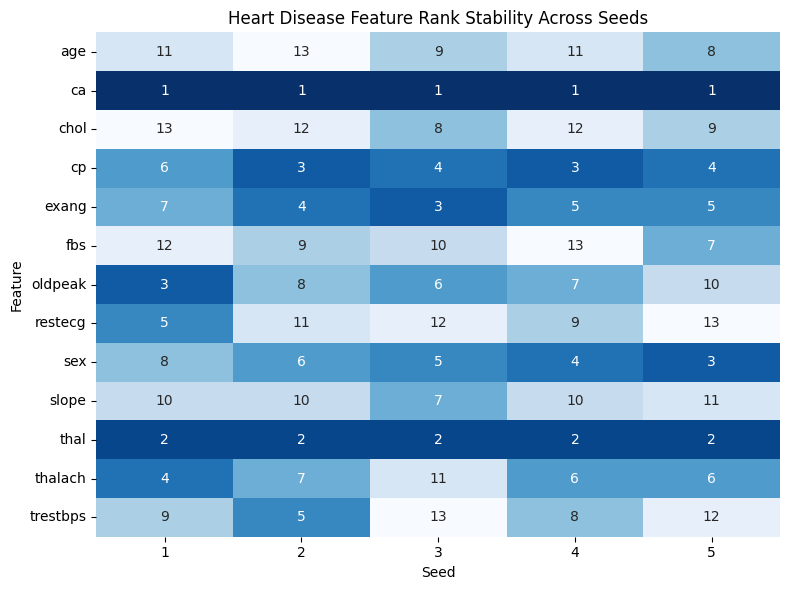

In [9]:
# -----------------------------
# 11. Stability analysis across seeds
# -----------------------------
seeds = [1, 2, 3, 4, 5]
stability_rows = []

for seed in seeds:
    X_train_s_df, X_test_s_df, y_train_s, y_test_s = train_test_split(
        X_df, y,
        test_size=0.3,
        random_state=seed,
        stratify=y
    )

    scaler_s = StandardScaler()
    X_train_s = scaler_s.fit_transform(X_train_s_df)
    X_test_s = scaler_s.transform(X_test_s_df)

    X_train_s = pd.DataFrame(X_train_s, columns=feature_names)
    X_test_s = pd.DataFrame(X_test_s, columns=feature_names)

    model_s = LogisticRegressionCV(
        Cs=10,
        cv=10,
        penalty='l2',
        solver='liblinear',
        max_iter=1000,
        random_state=seed
    )

    model_s.fit(X_train_s, y_train_s)

    perm_s = permutation_importance(
        model_s,
        X_test_s,
        y_test_s,
        n_repeats=10,
        random_state=seed,
        scoring="roc_auc"
    )

    temp = pd.DataFrame({
        "Feature": feature_names,
        "Importance": perm_s.importances_mean,
        "Seed": seed
    })

    stability_rows.append(temp)

stability_df = pd.concat(stability_rows, ignore_index=True)

stability_df["Rank"] = stability_df.groupby("Seed")["Importance"].rank(
    ascending=False,
    method="min"
)

stability_summary = stability_df.groupby("Feature").agg(
    MeanImportance=("Importance", "mean"),
    StdImportance=("Importance", "std"),
    MeanRank=("Rank", "mean"),
    StdRank=("Rank", "std")
).sort_values("MeanRank")

print("\nStability summary")
print(stability_summary.round(4))

rank_pivot = stability_df.pivot(index="Feature", columns="Seed", values="Rank")
print("\nFeature rank by seed")
print(rank_pivot)

plt.figure(figsize=(8, 6))
sns.heatmap(rank_pivot, annot=True, cmap="Blues_r", cbar=False)
plt.title("Heart Disease Feature Rank Stability Across Seeds")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "heart_rank_stability_heatmap.png"), dpi=300)
plt.show()


In [10]:
# -----------------------------
# 12. Final summary table
# -----------------------------
stability_export = stability_summary.reset_index()[["Feature", "MeanImportance", "MeanRank", "StdRank"]]

final_xai_summary = rank_compare.merge(
    stability_export,
    on="Feature",
    how="left"
).sort_values("SHAPRank")

print(final_xai_summary.round(4))

coef_df.to_csv(os.path.join(out_dir, "heart_lr_coefficients.csv"), index=False)
perm_df.to_csv(os.path.join(out_dir, "heart_permutation_importance.csv"), index=False)
shap_imp.to_csv(os.path.join(out_dir, "heart_shap_importance.csv"), index=False)
rank_compare.to_csv(os.path.join(out_dir, "heart_rank_compare.csv"), index=False)
stability_df.to_csv(os.path.join(out_dir, "heart_stability_raw.csv"), index=False)
stability_summary.to_csv(os.path.join(out_dir, "heart_stability_summary.csv"))
final_xai_summary.to_csv(os.path.join(out_dir, "heart_xai_final_summary.csv"), index=False)
lime_df.to_csv(os.path.join(out_dir, "heart_lime_cases.csv"), index=False)

print(f"\nAll heart XAI outputs saved to: {out_dir}")


     Feature  AbsCoefficient  CoefficientRank  MeanAbsSHAP  SHAPRank  \
0       thal          0.4788                1       0.4739         1   
1         ca          0.4443                2       0.3794         2   
2         cp          0.3343                3       0.2865         3   
3      exang          0.3122                4       0.2849         4   
4        sex          0.2821                5       0.2750         5   
5    oldpeak          0.2486                6       0.2028         6   
6    thalach          0.2205                7       0.2002         7   
7    restecg          0.1888                8       0.1873         8   
8      slope          0.1862                9       0.1740         9   
9   trestbps          0.1689               10       0.1430        10   
10       fbs          0.1251               11       0.0817        11   
11      chol          0.0998               12       0.0669        12   
12       age          0.0815               13       0.0664      

preparing for xai data agnostic pipeline

In [ ]:
xai_context = {
    "model": final_model,
    "X_train": X_train_enc,
    "X_test": X_test_enc,
    "y_train": y_train,
    "y_test": y_test,
    "feature_names": X_train_enc.columns.tolist(),
    "model_type": "random_forest"
}

In [11]:
def inspect_model(model):

    print("=" * 50)

    print("TYPE")
    print(type(model))

    print("\nCLASS")
    print(model.__class__.__name__)

    print("\nMODULE")
    print(model.__class__.__module__)

    print("\nCAPABILITIES")

    for attr in [
        "predict",
        "predict_proba",
        "coef_",
        "params",
        "feature_importances_"
    ]:

        print(
            f"{attr}:",
            hasattr(model, attr)
        )

    print("=" * 50)

In [12]:
inspect_model(final_model)

TYPE
<class 'sklearn.linear_model._logistic.LogisticRegressionCV'>

CLASS
LogisticRegressionCV

MODULE
sklearn.linear_model._logistic

CAPABILITIES
predict: True
predict_proba: True
coef_: True
params: False
feature_importances_: False
